In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")

In [2]:
np.random.seed(42)

n = 10000

data = {
    "CustomerID": range(10001, 10001 + n),

    "Age": np.random.randint(18, 65, n),

    "MonthlyIncome": np.random.lognormal(
        mean=10.8,
        sigma=0.45,
        size=n
    ).astype(int),

    "MonthlySpending": np.random.lognormal(
        mean=9.0,
        sigma=0.55,
        size=n
    ).astype(int),

    "CreditScore": np.clip(
        np.random.normal(700, 70, n),
        300,
        850
    ).astype(int),

    "TransactionsPerMonth": np.random.poisson(18, n),

    "AvgTransactionValue": np.random.lognormal(
        mean=7.0,
        sigma=0.5,
        size=n
    ).astype(int),

    "LoanAmount": np.maximum(
        0,
        np.random.normal(150000, 100000, n)
    ).astype(int),

    "InvestmentAmount": np.maximum(
        0,
        np.random.normal(80000, 70000, n)
    ).astype(int),

    "SavingsAmount": np.maximum(
        0,
        np.random.normal(100000, 80000, n)
    ).astype(int)
}

df = pd.DataFrame(data)

df.head()

,CustomerID,Age,MonthlyIncome,MonthlySpending,CreditScore,TransactionsPerMonth,AvgTransactionValue,LoanAmount,InvestmentAmount,SavingsAmount
0,10001,56,24138,10094,611,16,1022,0,0,61280
1,10002,46,31248,2553,673,20,1809,176902,19738,116750
2,10003,32,45173,9827,691,24,1532,96589,35343,132460
3,10004,60,63591,4483,625,17,1143,136083,64905,80130
4,10005,25,33228,3591,698,13,975,304189,0,124210


In [3]:
print("shape",df.shape)

shape (10000, 10)


In [4]:
df.isnull().sum()

,0
CustomerID,0
Age,0
MonthlyIncome,0
MonthlySpending,0
CreditScore,0
TransactionsPerMonth,0
AvgTransactionValue,0
LoanAmount,0
InvestmentAmount,0
SavingsAmount,0


In [5]:
df.describe()

,CustomerID,Age,MonthlyIncome,MonthlySpending,CreditScore,TransactionsPerMonth,AvgTransactionValue,LoanAmount,InvestmentAmount,SavingsAmount
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,15000.50000,41.054000,54218.392000,9408.951600,698.299200,18.009200,1230.186100,153152.643600,85512.685800,103952.43560
std,2886.89568,13.484104,25583.559431,5501.436024,69.516159,4.185865,646.539161,94851.652032,62714.079076,72630.63443
min,10001.00000,18.000000,7908.000000,1188.000000,435.000000,4.000000,168.000000,0.000000,0.000000,0.00000
25%,12500.75000,30.000000,36034.500000,5579.750000,652.000000,15.000000,778.000000,82526.500000,34684.250000,46408.50000
50%,15000.50000,41.000000,48967.000000,8131.000000,699.000000,18.000000,1089.000000,149664.000000,80884.000000,100058.50000
75%,17500.25000,53.000000,66289.750000,11768.250000,746.000000,21.000000,1523.000000,218805.500000,128772.750000,152988.00000
max,20000.00000,64.000000,247647.000000,70698.000000,850.000000,37.000000,6907.000000,528476.000000,352997.000000,381594.00000


In [6]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate Customer IDs:",
      df["CustomerID"].duplicated().sum())

Duplicate rows: 0
Duplicate Customer IDs: 0


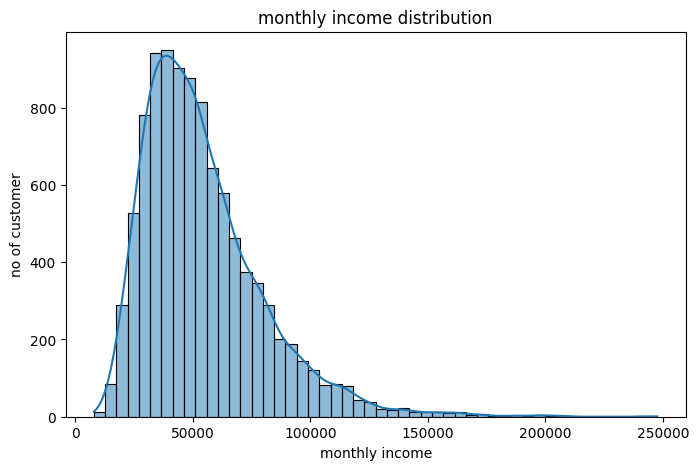

In [7]:
#monthly income distribution

plt.figure(figsize=(8,5))

sns.histplot(df["MonthlyIncome"],bins=50,kde=True)
plt.title("monthly income distribution")
plt.xlabel("monthly income")
plt.ylabel("no of customer")

plt.show()

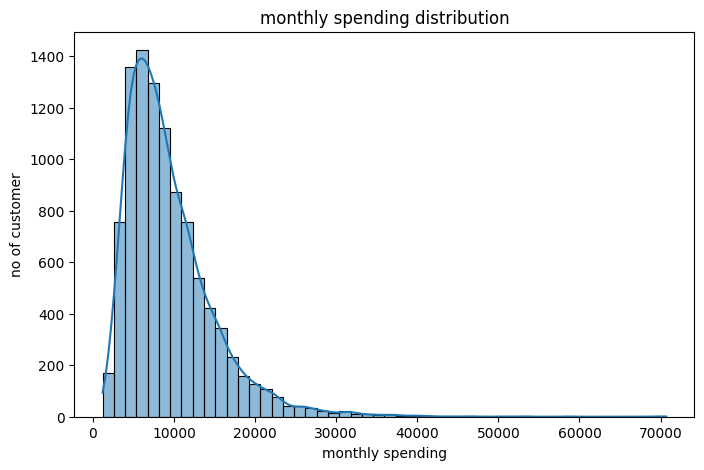

In [8]:
#spending distribution

plt.figure(figsize=(8,5))

sns.histplot(df["MonthlySpending"],bins=50,kde=True)
plt.title("monthly spending distribution")
plt.xlabel("monthly spending")
plt.ylabel("no of customer")

plt.show()

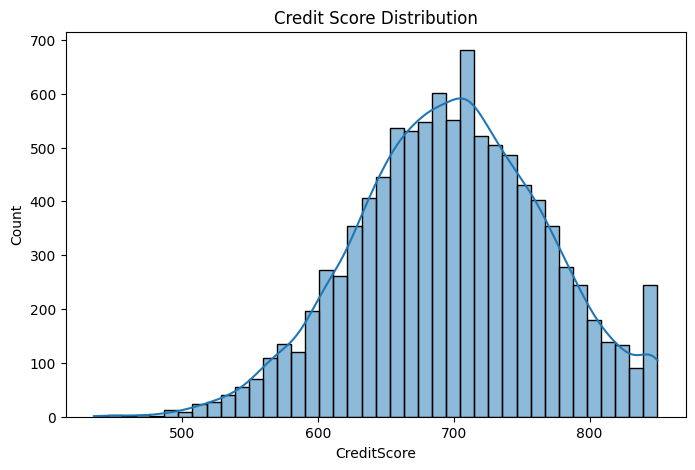

In [9]:
#credit score distribution

plt.figure(figsize=(8,5))

sns.histplot(df["CreditScore"], bins=40, kde=True)

plt.title("Credit Score Distribution")

plt.show()

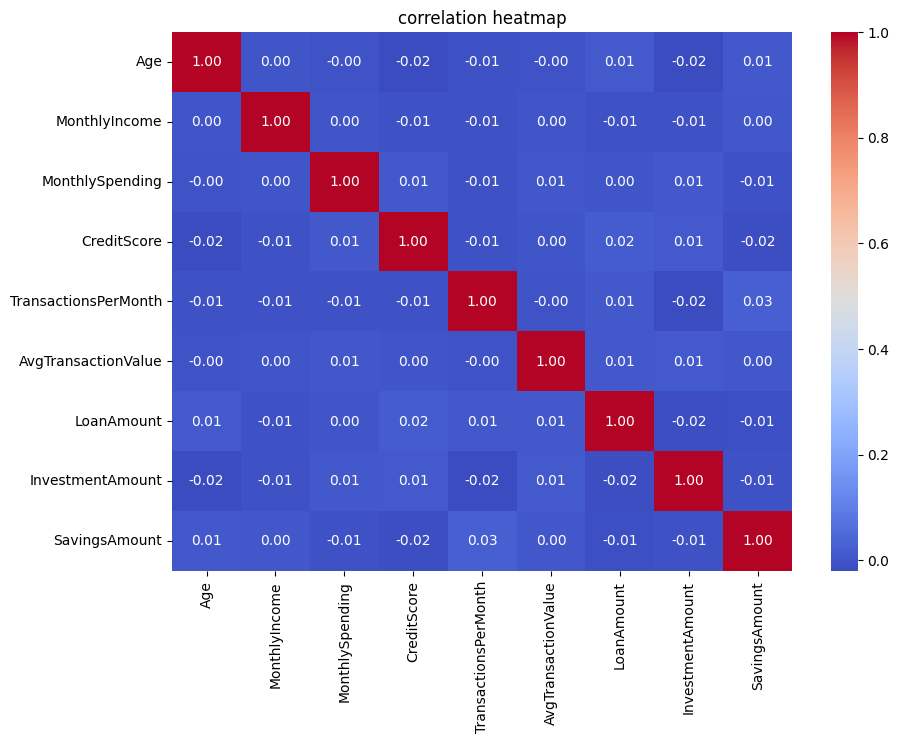

In [10]:
#correlation heatmap

plt.figure(figsize=(10,7))
sns.heatmap(
    df.drop("CustomerID",axis=1).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
  )
plt.title("correlation heatmap")
plt.show()

In [11]:
#selecting features for clustering , we are ignoring "CustomerID"

features = [
    "Age",
    "MonthlyIncome",
    "MonthlySpending",
    "CreditScore",
    "TransactionsPerMonth",
    "AvgTransactionValue",
    "LoanAmount",
    "InvestmentAmount",
    "SavingsAmount"
]

X = df[features]

X.head()

,Age,MonthlyIncome,MonthlySpending,CreditScore,TransactionsPerMonth,AvgTransactionValue,LoanAmount,InvestmentAmount,SavingsAmount
0,56,24138,10094,611,16,1022,0,0,61280
1,46,31248,2553,673,20,1809,176902,19738,116750
2,32,45173,9827,691,24,1532,96589,35343,132460
3,60,63591,4483,625,17,1143,136083,64905,80130
4,25,33228,3591,698,13,975,304189,0,124210


In [12]:
#feature scaling

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features
)

X_scaled.head()

,Age,MonthlyIncome,MonthlySpending,CreditScore,TransactionsPerMonth,AvgTransactionValue,LoanAmount,InvestmentAmount,SavingsAmount
0,1.108472,-1.175829,0.124528,-1.255874,-0.480020,-0.322017,-1.614735,-1.363601,-0.587556
1,0.366821,-0.897902,-1.246274,-0.363951,0.475624,0.895294,0.250397,-1.048855,0.176209
2,-0.671491,-0.353580,0.075993,-0.105005,1.431269,0.466838,-0.596368,-0.800015,0.392520
3,1.405132,0.366371,-0.895439,-1.054472,-0.241109,-0.134857,-0.179970,-0.328614,-0.328011
4,-1.190647,-0.820505,-1.057586,-0.004304,-1.196754,-0.394715,1.592423,-1.363601,0.278926


In [13]:
inertia=[]

K_range=range(2,11)

for k in K_range:
  kmeans=KMeans(
      n_clusters=k,
      random_state=42,
      n_init=10
  )

  kmeans.fit(X_scaled)

  inertia.append(kmeans.inertia_)

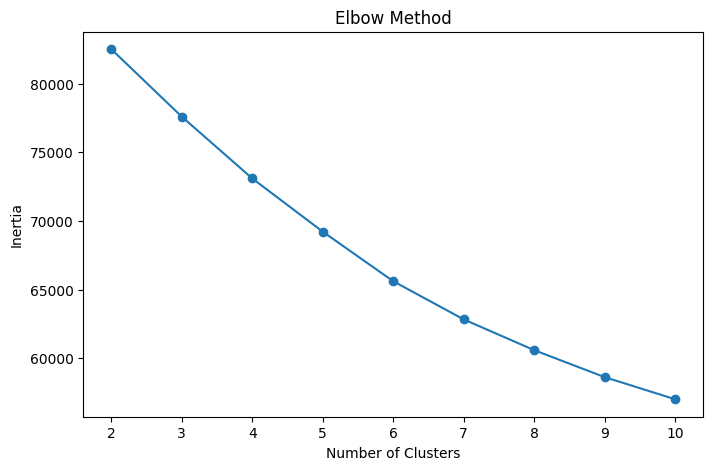

In [14]:
plt.figure(figsize=(8,5))

plt.plot(K_range, inertia, marker="o")

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.title("Elbow Method")

plt.show()

In [15]:
from sklearn.metrics import silhouette_score

# Silhouette Score
silhouette_scores = []

for k in range(2, 11):
  kmeans = KMeans(
      n_clusters=k,
      random_state=42,
      n_init=10
  )

  labels = kmeans.fit_predict(X_scaled)

  score = silhouette_score(X_scaled, labels)
  silhouette_scores.append(score)

  print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.0875
K = 3, Silhouette Score = 0.0880
K = 4, Silhouette Score = 0.0891
K = 5, Silhouette Score = 0.0879
K = 6, Silhouette Score = 0.0889
K = 7, Silhouette Score = 0.0870
K = 8, Silhouette Score = 0.0850
K = 9, Silhouette Score = 0.0858
K = 10, Silhouette Score = 0.0843


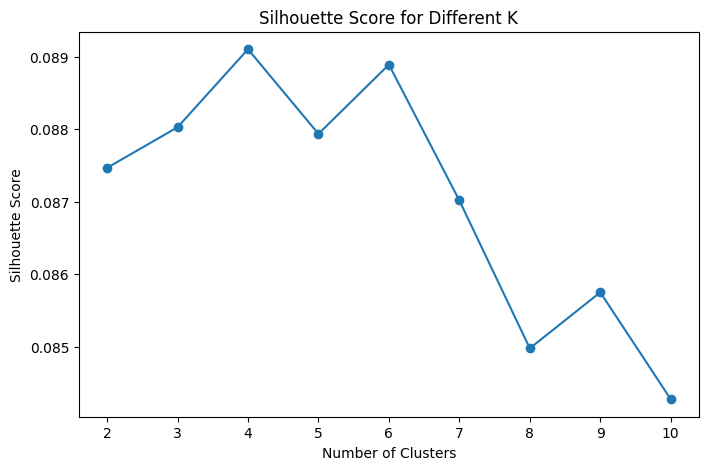

In [16]:
plt.figure(figsize=(8,5))

plt.plot(
    range(2,11),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.title("Silhouette Score for Different K")

plt.show()

In [17]:
df.head()

,CustomerID,Age,MonthlyIncome,MonthlySpending,CreditScore,TransactionsPerMonth,AvgTransactionValue,LoanAmount,InvestmentAmount,SavingsAmount
0,10001,56,24138,10094,611,16,1022,0,0,61280
1,10002,46,31248,2553,673,20,1809,176902,19738,116750
2,10003,32,45173,9827,691,24,1532,96589,35343,132460
3,10004,60,63591,4483,625,17,1143,136083,64905,80130
4,10005,25,33228,3591,698,13,975,304189,0,124210


In [18]:
kmeans=KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)
df["cluster"]=kmeans.fit_predict(X_scaled)
df.head()

,CustomerID,Age,MonthlyIncome,MonthlySpending,CreditScore,TransactionsPerMonth,AvgTransactionValue,LoanAmount,InvestmentAmount,SavingsAmount,cluster
0,10001,56,24138,10094,611,16,1022,0,0,61280,3
1,10002,46,31248,2553,673,20,1809,176902,19738,116750,3
2,10003,32,45173,9827,691,24,1532,96589,35343,132460,0
3,10004,60,63591,4483,625,17,1143,136083,64905,80130,3
4,10005,25,33228,3591,698,13,975,304189,0,124210,0


In [19]:
print(df["cluster"].value_counts())

cluster
3    3630
0    3608
1    1498
2    1264
Name: count, dtype: int64


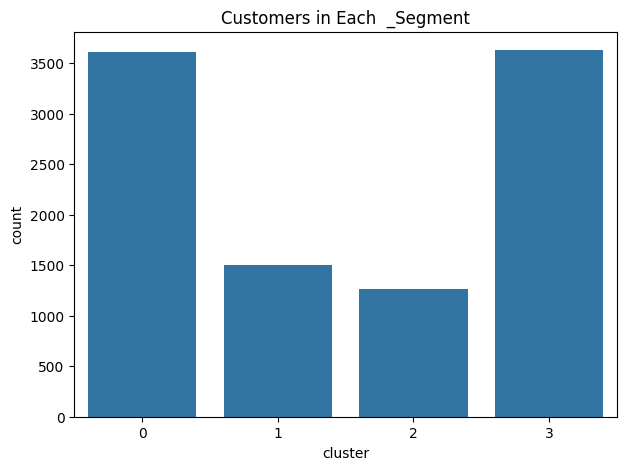

In [20]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="cluster"
)

plt.title("Customers in Each  _Segment")

plt.show()

In [21]:
cluster_profile = df.groupby("cluster")[features].mean()

cluster_profile.round(2)

,Age,MonthlyIncome,MonthlySpending,CreditScore,TransactionsPerMonth,AvgTransactionValue,LoanAmount,InvestmentAmount,SavingsAmount
cluster,,,,,,,,,
0,29.00,45356.92,7749.12,703.28,18.32,1225.85,148427.61,90424.39,102073.67
1,40.32,99111.54,8621.92,694.70,17.71,1256.68,147469.33,82237.41,107272.21
2,41.13,49679.49,19986.02,695.79,17.79,1262.14,150451.88,89736.88,99222.30
3,53.31,46080.49,7700.48,695.71,17.90,1212.43,161134.82,80511.47,106096.92


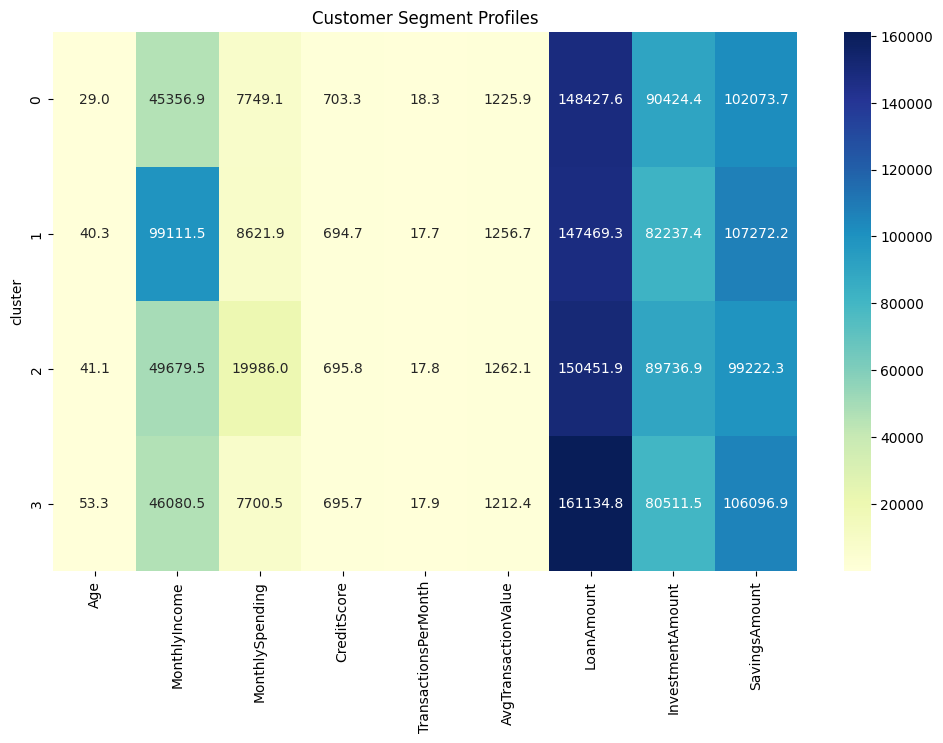

In [22]:

plt.figure(figsize=(12,7))

sns.heatmap(
    cluster_profile,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Customer Segment Profiles")

plt.show()

In [23]:
#PCA

pca=PCA(n_components=2)

X_pca=pca.fit_transform(X_scaled)
df["PC1"]= X_pca[:,0]
df["PCA2"] = X_pca[:, 1]

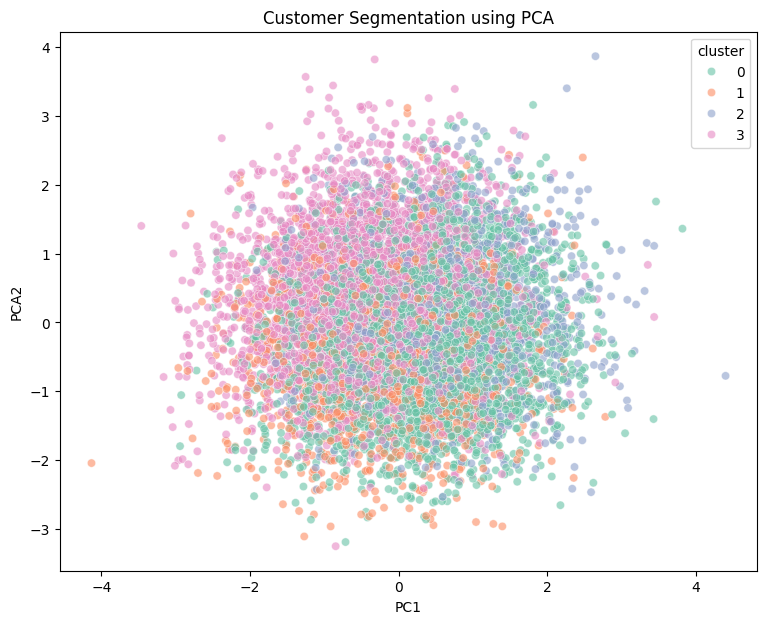

In [24]:
plt.figure(figsize=(9,7))

sns.scatterplot(
    data=df,
    x="PC1",
    y="PCA2",
    hue="cluster",
    palette="Set2",
    alpha=0.6
)

plt.title("Customer Segmentation using PCA")

plt.show()

In [25]:
cluster_profile.round(0)

,Age,MonthlyIncome,MonthlySpending,CreditScore,TransactionsPerMonth,AvgTransactionValue,LoanAmount,InvestmentAmount,SavingsAmount
cluster,,,,,,,,,
0,29.0,45357.0,7749.0,703.0,18.0,1226.0,148428.0,90424.0,102074.0
1,40.0,99112.0,8622.0,695.0,18.0,1257.0,147469.0,82237.0,107272.0
2,41.0,49679.0,19986.0,696.0,18.0,1262.0,150452.0,89737.0,99222.0
3,53.0,46080.0,7700.0,696.0,18.0,1212.0,161135.0,80511.0,106097.0


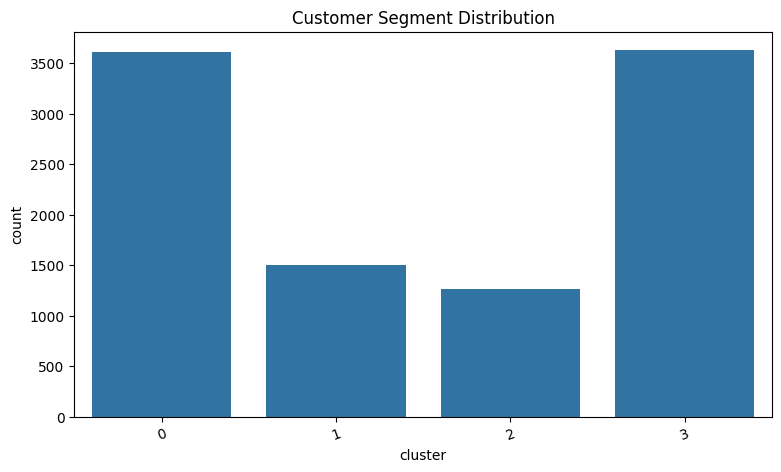

In [26]:
plt.figure(figsize=(9,5))

sns.countplot(
    data=df,
    x="cluster"
)

plt.xticks(rotation=20)

plt.title("Customer Segment Distribution")

plt.show()

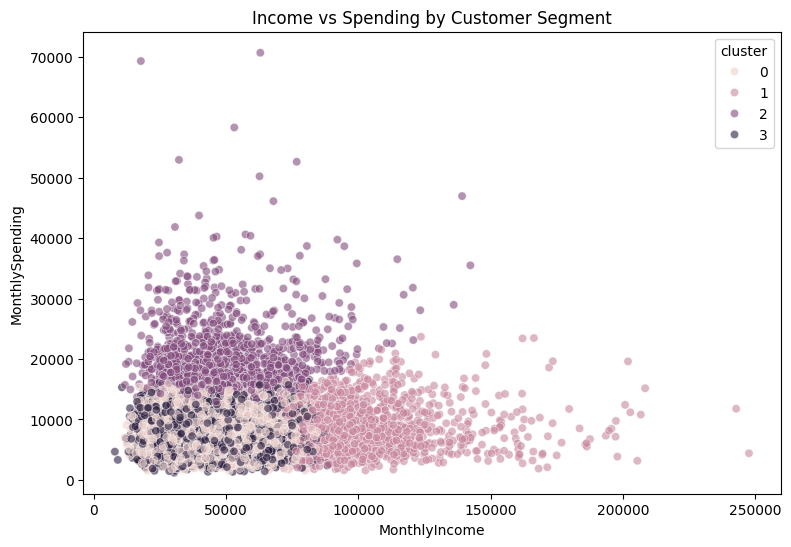

In [27]:
plt.figure(figsize=(9,6))

sns.scatterplot(
    data=df,
    x="MonthlyIncome",
    y="MonthlySpending",
    hue="cluster",
    alpha=0.6
)

plt.title("Income vs Spending by Customer Segment")

plt.show()

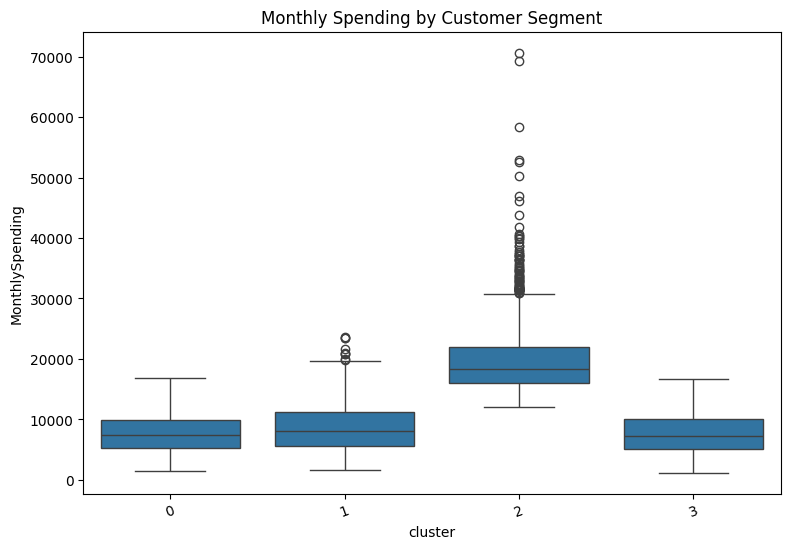

In [28]:
plt.figure(figsize=(9,6))

sns.boxplot(
    data=df,
    x="cluster",
    y="MonthlySpending"
)

plt.xticks(rotation=20)

plt.title("Monthly Spending by Customer Segment")

plt.show()

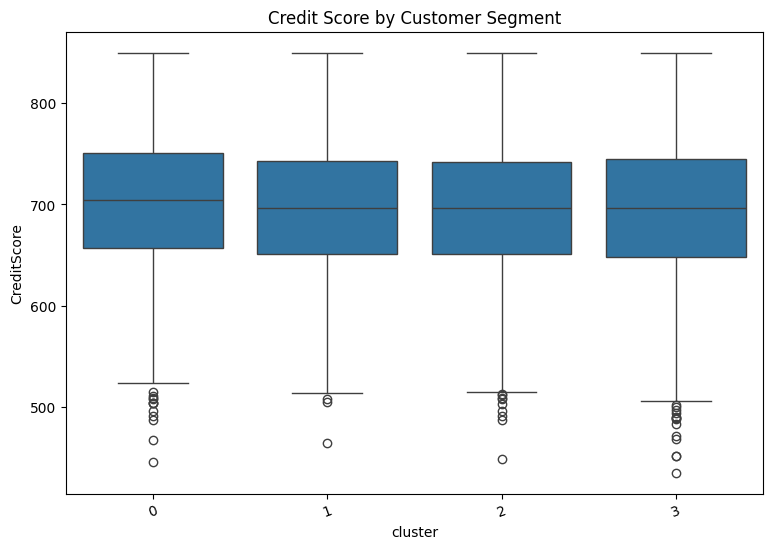

In [29]:
plt.figure(figsize=(9,6))

sns.boxplot(
    data=df,
    x="cluster",
    y="CreditScore"
)

plt.xticks(rotation=20)

plt.title("Credit Score by Customer Segment")

plt.show()

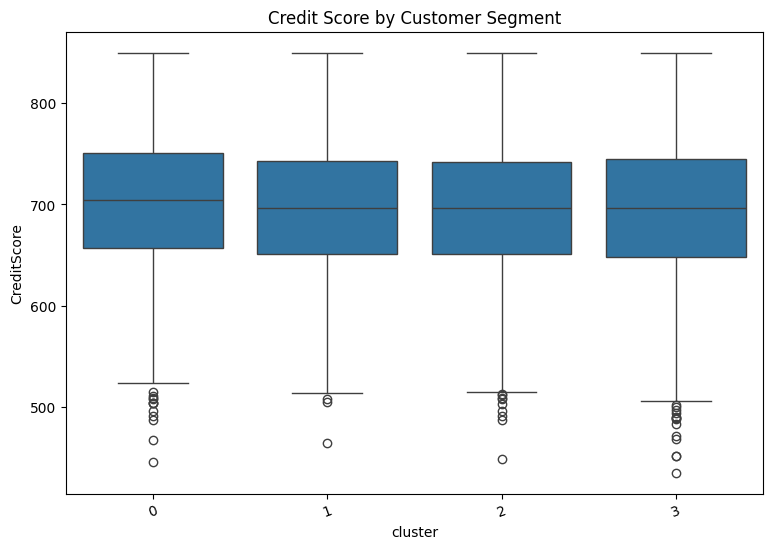

In [30]:
plt.figure(figsize=(9,6))

sns.boxplot(
    data=df,
    x="cluster",
    y="CreditScore"
)

plt.xticks(rotation=20)

plt.title("Credit Score by Customer Segment")

plt.show()

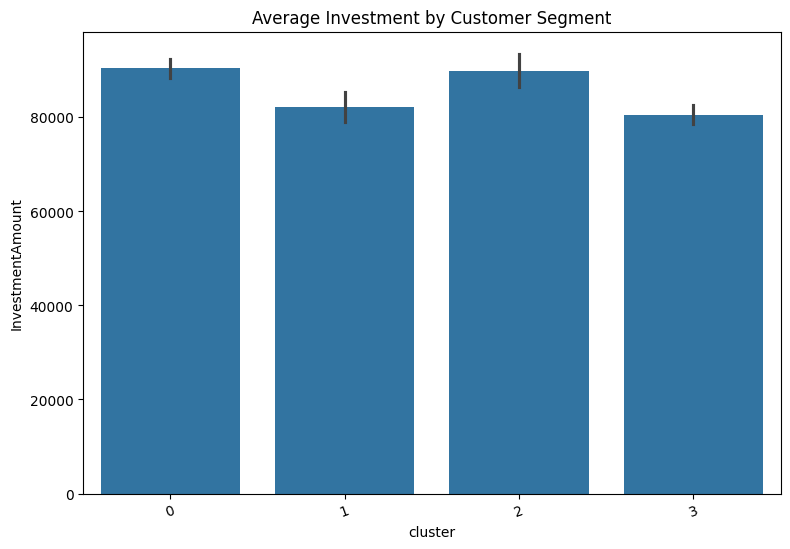

In [31]:
plt.figure(figsize=(9,6))

sns.barplot(
    data=df,
    x="cluster",
    y="InvestmentAmount"
)

plt.xticks(rotation=20)

plt.title("Average Investment by Customer Segment")

plt.show()

In [32]:
final_profile = df.groupby(
    "cluster"
)[features].mean().round(2)

final_profile

,Age,MonthlyIncome,MonthlySpending,CreditScore,TransactionsPerMonth,AvgTransactionValue,LoanAmount,InvestmentAmount,SavingsAmount
cluster,,,,,,,,,
0,29.00,45356.92,7749.12,703.28,18.32,1225.85,148427.61,90424.39,102073.67
1,40.32,99111.54,8621.92,694.70,17.71,1256.68,147469.33,82237.41,107272.21
2,41.13,49679.49,19986.02,695.79,17.79,1262.14,150451.88,89736.88,99222.30
3,53.31,46080.49,7700.48,695.71,17.90,1212.43,161134.82,80511.47,106096.92
